In [ ]:
!nvidia-smi

Thu Jun  4 10:12:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Kerangka Klasifikasi Hoaks Multi-Layer untuk Konten Digital Indonesia
## Integrasi Semantic Embeddings (IndoBERT), Machine Learning, dan Analisis Pakar (LLM)

**Penulis:** Feriyan  
**Tujuan:** Penelitian Ilmiah (PI) - Deteksi Disinformasi pada Media Digital Indonesia

### 📑 Ringkasan Eksekutif
Sistem ini dirancang untuk mendeteksi berita palsu (hoaks) dalam konteks bahasa Indonesia dengan tingkat akurasi dan reliabilitas tinggi. Perbedaan utama sistem ini dengan pendekatan tradisional adalah penggunaan **Arsitektur Multi-Layer**:

1.  **Layer Fitur Semantik (Deep Learning)**: Menggunakan model Transformer **IndoBERT** untuk menangkap makna kontekstual yang dalam dari teks berita.
2.  **Layer Klasifikasi Robust (Machine Learning)**: Implementasi SVM dan Random Forest dengan penanganan ketidakseimbangan data (Class Weighting).
3.  **Layer Analisis Pakar (LLM/GPT)**: Verifikasi analitis terhadap pola retika dan logika berita.
4.  **Layer Kredibilitas Sumber**: Pengecekan otoritas domain (Domain Authority/Rating) dari sumber berita untuk mendeteksi situs-situs yang tidak kredibel atau mencurigakan.

---



# 🛠️ Bagian 1: Data Acquisition (Scraping)
Bagian ini berfokus pada pengumpulan dataset dari berbagai sumber berita di Indonesia. Kami mengumpulkan data artikel yang sudah terverifikasi sebagai **Fakta** (dari media arus utama) dan **Hoaks** (dari database verifikator berita seperti TurnBackHoax).

**Prinsip Profesional ML:**
- **Robustness**: Menggunakan **BeautifulSoup** untuk memastikan hanya teks bersih yang diambil, menghindari kebocoran kode HTML/JS ke dalam model.
- **Efisiensi**: Implementasi **ThreadPoolExecutor** untuk proses pengambilan data secara paralel (multithreading).
- **Etika Scraping**: Penambahan headers User-Agent dan timeout untuk menjaga stabilitas koneksi ke server sumber.



In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = "https://www.kompas.com/cekfakta/data-dan-fakta/{}"
HEADERS = {
    "User-Agent": "Mozilla/5.0"
}


def request_html(url: str) -> str:
    """Retrieve HTML from a given URL."""
    try:
        res = requests.get(url, headers=HEADERS, timeout=10)
        res.raise_for_status()
        return res.text
    except requests.RequestException:
        return ""


def find_links(html: str) -> List[str]:
    """Extract cekfakta article links."""
    matches = re.findall(r'href="(.*?)"', html)
    return [link for link in matches if "cekfakta/read" in link]


def gather_links(pages: int = 60) -> List[str]:
    """Collect unique article URLs across pages."""
    collected = set()

    for i in range(1, pages + 1):
        url = BASE_URL.format(i)
        html = request_html(url)
        if not html:
            continue

        links = find_links(html)
        collected.update(links)

    return list(collected)


def parse_page(html: str) -> Dict[str, str]:
    """Extract title and body text from article page."""

    # Title
    title_match = re.search(r'<h1 class="read__title">(.*?)</h1>', html)
    title = title_match.group(1).strip() if title_match else None

    # Content block
    content_match = re.search(
        r'<div\s+[^>]*class=["\']read__content["\'][^>]*>(.*?)</div>',
        html,
        re.DOTALL
    )

    if not content_match:
        return {}

    raw = content_match.group(1)

    # Paragraph extraction
    paragraphs = re.findall(r'<p[^>]*>(.*?)</p>', raw, re.DOTALL)
    text = " ".join(paragraphs)
    text = re.sub(r'<[^>]+>', '', text).strip()

    if not title or not text:
        return {}

    return {
        "TITLE": title,
        "NARRATIVE": text,
        "LABEL": 1
    }


def process_link(url: str) -> Dict[str, str]:
    """Fetch and parse a single article."""
    html = request_html(url)
    if not html:
        return {}

    return parse_page(html)


def scrape_articles_parallel(links: List[str], workers: int = 10) -> List[Dict]:
    """Fetch articles concurrently using threads."""
    results = []

    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = [executor.submit(process_link, link) for link in links]

        for i, future in enumerate(as_completed(futures), 1):
            data = future.result()
            if data:
                results.append(data)

            print(f"[{i}/{len(links)}] done")

    return results


def save_csv(data: List[Dict], filename: str = "kompas_dataset.csv"):
    """Write dataset to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved to {filename}")


if __name__ == "__main__":
    links = gather_links(pages=80)
    print(f"Collected {len(links)} links")

    articles = scrape_articles_parallel(links, workers=10)
    print(f"Collected {len(articles)} articles")

    save_csv(articles)

Collected 1088 links
[1/1088] done
[2/1088] done
[3/1088] done
[4/1088] done
[5/1088] done
[6/1088] done
[7/1088] done
[8/1088] done
[9/1088] done
[10/1088] done
[11/1088] done
[12/1088] done
[13/1088] done
[14/1088] done
[15/1088] done
[16/1088] done
[17/1088] done
[18/1088] done
[19/1088] done
[20/1088] done
[21/1088] done
[22/1088] done
[23/1088] done
[24/1088] done
[25/1088] done
[26/1088] done
[27/1088] done
[28/1088] done
[29/1088] done
[30/1088] done
[31/1088] done
[32/1088] done
[33/1088] done
[34/1088] done
[35/1088] done
[36/1088] done
[37/1088] done
[38/1088] done
[39/1088] done
[40/1088] done
[41/1088] done
[42/1088] done
[43/1088] done
[44/1088] done
[45/1088] done
[46/1088] done
[47/1088] done
[48/1088] done
[49/1088] done
[50/1088] done
[51/1088] done
[52/1088] done
[53/1088] done
[54/1088] done
[55/1088] done
[56/1088] done
[57/1088] done
[58/1088] done
[59/1088] done
[60/1088] done
[61/1088] done
[62/1088] done
[63/1088] done
[64/1088] done
[65/1088] done
[66/1088] don

# Scrape Detik Fact

In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = "https://www.detik.com/tag/news/fakta/?sortby=time&page={}"
HEADERS = {
    "User-Agent": "Mozilla/5.0"
}


def get_html(url: str) -> str:
    """Request page HTML safely."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=10)
        r.raise_for_status()
        return r.text
    except:
        return ""


def collect_links(html: str) -> List[str]:
    """Parse listing page and extract article URLs."""
    soup = BeautifulSoup(html, "html.parser")
    results = []

    for tag in soup.select('article a[href*="/d-"]'):
        link = tag.get("href")
        if link:
            results.append(link)

    return results


def gather_all_links(max_pages: int = 13) -> List[str]:
    """Loop through pages and gather unique links."""
    links = set()

    for page in range(1, max_pages + 1):
        url = BASE_URL.format(page)
        html = get_html(url)

        if not html:
            continue

        links.update(collect_links(html))

    return list(links)


def extract_article(html: str) -> Dict[str, str]:
    """Extract title + cleaned article text."""
    soup = BeautifulSoup(html, "html.parser")

    # Title via JSON-LD
    match = re.search(r'"headline":\s*"(.*?)"', html)
    title = match.group(1).strip() if match else None

    container = soup.select_one(".detail__body-text")
    if not container:
        return {}

    texts = []
    for p in container.find_all("p"):
        t = p.get_text(strip=True)

        if not t or "ADVERTISEMENT" in t:
            continue

        texts.append(t)

    content = " ".join(texts).strip()

    # Remove prefix like "Jakarta -"
    content = re.sub(r'^[A-Za-z\s]+-\s*', '', content)

    if not title or not content:
        return {}

    return {
        "TITLE": title,
        "NARRATIVE": content,
        "LABEL": 1
    }


def process_link(link: str) -> Dict[str, str]:
    """Fetch + parse single article."""
    html = get_html(link)
    if not html:
        return {}

    return extract_article(html)


def scrape_all_articles(links: List[str], workers: int = 10) -> List[Dict]:
    """Scrape articles concurrently."""
    dataset = []

    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = {executor.submit(process_link, link): link for link in links}

        for i, future in enumerate(as_completed(futures), 1):
            result = future.result()
            if result:
                dataset.append(result)

            print(f"[{i}/{len(links)}] done")

    return dataset


def export_csv(data: List[Dict], filename: str = "detik_dataset.csv"):
    """Save dataset to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved: {filename}")


if __name__ == "__main__":
    links = gather_all_links(max_pages=13)
    print(f"Total links: {len(links)}")

    articles = scrape_all_articles(links, workers=10)
    print(f"Total articles: {len(articles)}")

    export_csv(articles)

Total links: 131
[1/131] done
[2/131] done
[3/131] done
[4/131] done
[5/131] done
[6/131] done
[7/131] done
[8/131] done
[9/131] done
[10/131] done
[11/131] done
[12/131] done
[13/131] done
[14/131] done
[15/131] done
[16/131] done
[17/131] done
[18/131] done
[19/131] done
[20/131] done
[21/131] done
[22/131] done
[23/131] done
[24/131] done
[25/131] done
[26/131] done
[27/131] done
[28/131] done
[29/131] done
[30/131] done
[31/131] done
[32/131] done
[33/131] done
[34/131] done
[35/131] done
[36/131] done
[37/131] done
[38/131] done
[39/131] done
[40/131] done
[41/131] done
[42/131] done
[43/131] done
[44/131] done
[45/131] done
[46/131] done
[47/131] done
[48/131] done
[49/131] done
[50/131] done
[51/131] done
[52/131] done
[53/131] done
[54/131] done
[55/131] done
[56/131] done
[57/131] done
[58/131] done
[59/131] done
[60/131] done
[61/131] done
[62/131] done
[63/131] done
[64/131] done
[65/131] done
[66/131] done
[67/131] done
[68/131] done
[69/131] done
[70/131] done
[71/131] don

## Scrape Komdigi

### Fact News

In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = "https://web.komdigi.go.id/api/v1/contents/category/berita-pemerintahan"
DETAIL_URL = "https://web.komdigi.go.id/api/v1/content/detail/berita-pemerintahan/{}"

HEADERS = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
    "Referer": "https://www.komdigi.go.id/",
    "Origin": "https://www.komdigi.go.id"
}


def request_json(url: str) -> Dict:
    """Send GET request and return JSON."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=10)
        r.raise_for_status()
        return r.json()
    except:
        return {}


def collect_slugs(max_pages: int = 10) -> List[str]:
    """Retrieve unique slugs from paginated API."""
    slugs = set()

    for page in range(1, max_pages + 1):
        url = f"{BASE_URL}?perPage=12&page={page}&keyword="
        data = request_json(url)

        items = data.get("response", {}).get("data", [])
        for item in items:
            slug = item.get("slug")
            if slug:
                slugs.add(slug)

        print(f"[Page {page}] {len(items)} items")

    return list(slugs)


def strip_html(raw: str) -> str:
    """Clean HTML tags from text."""
    return re.sub(r"<[^>]+>", "", raw).strip()


def parse_detail(slug: str) -> Dict:
    """Fetch and parse single article."""
    url = DETAIL_URL.format(slug)
    data = request_json(url)

    article = data.get("data", {})
    title = article.get("title")
    body = strip_html(article.get("body", ""))

    if not title or not body:
        return {}

    return {
        "TITLE": title,
        "NARRATIVE": body,
        "LABEL": 1
    }


def scrape_parallel(slugs: List[str], workers: int = 10) -> List[Dict]:
    """Fetch articles concurrently."""
    results = []

    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = {executor.submit(parse_detail, slug): slug for slug in slugs}

        for i, future in enumerate(as_completed(futures), 1):
            data = future.result()
            if data:
                results.append(data)

            if i % 10 == 0 or i == len(slugs):
                print(f"[{i}/{len(slugs)}] processed")

    return results


def export_csv(data: List[Dict], filename: str):
    """Write dataset to CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} rows → {filename}")


if __name__ == "__main__":
    print("Collecting slugs...")
    slugs = collect_slugs(max_pages=30)
    print(f"Total slugs: {len(slugs)}")

    print("\nScraping articles (multithread)...")
    articles = scrape_parallel(slugs, workers=30)

    export_csv(articles, "komdigi_fact_dataset.csv")

    print("\nPreview:")
    print(pd.DataFrame(articles).head())

[Page 1] 12 items
[Page 2] 12 items
[Page 3] 12 items
[Page 4] 12 items
[Page 5] 12 items
[Page 6] 12 items
[Page 7] 12 items
[Page 8] 12 items
[Page 9] 12 items
[Page 10] 12 items
[Page 11] 12 items
[Page 12] 12 items
[Page 13] 12 items
[Page 14] 12 items
[Page 15] 12 items
[Page 16] 12 items
[Page 17] 12 items
[Page 18] 12 items
[Page 19] 12 items
[Page 20] 12 items
[Page 21] 12 items
[Page 22] 12 items
[Page 23] 12 items
[Page 24] 12 items
[Page 25] 12 items
[Page 26] 12 items
[Page 27] 12 items
[Page 28] 12 items
[Page 29] 12 items
[Page 30] 12 items
Total slugs: 357

Scraping articles (multithread)...
[10/357] processed
[20/357] processed
[30/357] processed
[40/357] processed
[50/357] processed
[60/357] processed
[70/357] processed
[80/357] processed
[90/357] processed
[100/357] processed
[110/357] processed
[120/357] processed
[130/357] processed
[140/357] processed
[150/357] processed
[160/357] processed
[170/357] processed
[180/357] processed
[190/357] processed
[200/357] proce

### Fake News

In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = "https://web.komdigi.go.id/api/v1/contents/category/berita-hoaks"
DETAIL_URL = "https://web.komdigi.go.id/api/v1/content/detail/berita-hoaks/{}"

HEADERS = {
    "User-Agent": "Mozilla/5.0",
    "Accept": "*/*",
    "Referer": "https://www.komdigi.go.id/",
    "Origin": "https://www.komdigi.go.id"
}


def request_json(url: str) -> Dict:
    """GET request → JSON response."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=10)
        r.raise_for_status()
        return r.json()
    except:
        return {}


def collect_slugs(max_pages: int = 10) -> List[str]:
    """Gather unique slugs from paginated endpoint."""
    slugs = set()

    for page in range(1, max_pages + 1):
        url = f"{BASE_URL}?perPage=12&page={page}&keyword="
        data = request_json(url)

        items = data.get("response", {}).get("data", [])
        for item in items:
            slug = item.get("slug")
            if slug:
                slugs.add(slug)

        print(f"[Page {page}] {len(items)} items")

    return list(slugs)


def strip_html(text: str) -> str:
    """Remove HTML tags."""
    return re.sub(r"<[^>]+>", "", text).strip()


def parse_article(slug: str) -> Dict:
    """Fetch and clean single article."""
    url = DETAIL_URL.format(slug)
    data = request_json(url)

    article = data.get("data", {})
    title = article.get("title")
    content = strip_html(article.get("body", ""))

    if not title or not content:
        return {}

    return {
        "TITLE": title,
        "NARRATIVE": content,
        "LABEL": 0   # hoax label
    }


def scrape_parallel(slugs: List[str], workers: int = 10) -> List[Dict]:
    """Concurrent scraping for all slugs."""
    results = []

    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = {executor.submit(parse_article, slug): slug for slug in slugs}

        for i, future in enumerate(as_completed(futures), 1):
            res = future.result()
            if res:
                results.append(res)

            if i % 10 == 0 or i == len(slugs):
                print(f"[{i}/{len(slugs)}] processed")

    return results


def export_csv(data: List[Dict], filename: str):
    """Save results into CSV."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} rows → {filename}")


if __name__ == "__main__":
    print("Collecting slugs...")
    slugs = collect_slugs(max_pages=10)
    print(f"Total slugs: {len(slugs)}")

    print("\nScraping articles (multithread)...")
    articles = scrape_parallel(slugs, workers=10)

    export_csv(articles, "komdigi_hoax_dataset.csv")

    print("\nPreview:")
    print(pd.DataFrame(articles).head())

[Page 1] 0 items
[Page 2] 0 items
[Page 3] 0 items
[Page 4] 0 items
[Page 5] 0 items
[Page 6] 0 items
[Page 7] 0 items
[Page 8] 0 items
[Page 9] 0 items
[Page 10] 0 items
Total slugs: 0

Scraping articles (multithread)...
Saved 0 rows → komdigi_hoax_dataset.csv

Preview:
Empty DataFrame
Columns: []
Index: []


## Scrape TurnBackHoax

In [ ]:
import requests
import re
import pandas as pd
from typing import List, Dict
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor, as_completed

BASE_URL = "https://turnbackhoax.id/articles?category=all&page={}"
HEADERS = {
    "User-Agent": "Mozilla/5.0"
}

def get_html(url: str) -> str:
    """Fetch page HTML."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=10)
        r.raise_for_status()
        return r.text
    except:
        return ""

def extract_links(html_content: str) -> List[str]:
    """Extract article URLs from listing page using BeautifulSoup."""
    soup = BeautifulSoup(html_content, "html.parser")
    # Finding links with the specified layout class
    links = [a['href'] for a in soup.find_all('a', class_="flex flex-col gap-1 lg:gap-2", href=True)]
    return links

def gather_links(max_pages: int = 50) -> List[str]:
    """Iterate pages and collect unique links."""
    links = set()
    for page in range(1, max_pages + 1):
        url = BASE_URL.format(page)
        html = get_html(url)
        found = extract_links(html)
        if not found:
            print(f"Stop at page {page} (no links found)")
            break
        links.update(found)
        print(f"[Page {page}] +{len(found)} (Total: {len(links)})")
    return list(links)

def parse_article(html_content: str) -> Dict:
    """Fetch and parse a single article using BeautifulSoup for reliable cleaning."""
    soup = BeautifulSoup(html_content, "html.parser")
    try:
        # Title
        title_tag = soup.find("h1", class_="text-3xl md:text-4xl md:leading-none")
        title = title_tag.get_text(strip=True) if title_tag else None

        # Content: Extract text from all paragraphs efficiently
        # Remove common noise elements first if found
        for unwanted in soup(["script", "style", "table", "footer"]):
            unwanted.decompose()

        paragraphs = soup.find_all("p")
        text_content = []
        for p in paragraphs:
            txt = p.get_text(strip=True)
            if not txt or "Baca juga:" in txt:
                continue
            text_content.append(txt)

        content = " ".join(text_content).strip()

        if not title or not content:
            return {}

        return {
            "TITLE": title,
            "NARRATIVE": content,
            "LABEL": 0
        }
    except Exception:
        return {}

def scrape_parallel(links: List[str], workers: int = 12) -> List[Dict]:
    """Run multithreaded scraping."""
    results = []
    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = {executor.submit(parse_article, get_html(link)): link for link in links if link}
        for i, future in enumerate(as_completed(futures), 1):
            data = future.result()
            if data:
                results.append(data)
            if i % 20 == 0 or i == len(links):
                print(f"[{i}/{len(links)}] processed")
    return results

def save_csv(data: List[Dict], filename: str):
    """Export dataset."""
    df = pd.DataFrame(data)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} rows → {filename}")

if __name__ == "__main__":
    print("Collecting links from TurnBackHoax...")
    links = gather_links(max_pages=50)
    print(f"Total links: {len(links)}")

    print("\nScraping articles...")
    articles = scrape_parallel(links, workers=12)

    save_csv(articles, "turnbackhoax_dataset.csv")

    print("\nPreview:")
    print(pd.DataFrame(articles).head())



[Page 1] +10 (Total: 10)
[Page 2] +10 (Total: 20)
[Page 3] +10 (Total: 30)
[Page 4] +10 (Total: 40)
[Page 5] +10 (Total: 50)
[Page 6] +10 (Total: 60)
Stop at page 7 (no links found)
Total links: 60

Scraping articles...


# 🧹 Bagian 2: Data Preparation & Sanitization
Setelah data dikumpulkan dari berbagai sumber, langkah krusial berikutnya adalah membersihkan dan menyatukan data ke dalam format yang konsisten.

**Pekerjaan Utama:**
1.  **Normalisasi Kolom**: Penyatuan nama kolom menjadi TITLE, NARRATIVE, dan LABEL.
2.  **Deduplikasi**: Menghapus artikel ganda yang mungkin terambil dari beberapa sumber berbeda.
3.  **Data Recovery & Scrubbing**: Membersihkan sisa-sisa noise HTML/JS yang tertinggal untuk memastikan input model berkualitas tinggi.



## Merge Dataset To One File

In [ ]:
import pandas as pd
from typing import List

DATA_FILES = [
    'kompas_dataset.csv',
    'detik_dataset.csv',
    'komdigi_fact_dataset.csv',
    'komdigi_hoax_dataset.csv',
    'turnbackhoax_dataset.csv'
]


def normalize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Unify column names into TITLE, NARRATIVE, LABEL format."""
    df.columns = [c.upper() for c in df.columns]

    rename_map = {
        "NARASI": "NARRATIVE",
        "CONTENT": "NARRATIVE",
        "TEXT": "NARRATIVE"
    }

    df = df.rename(columns=rename_map)

    required = {"TITLE", "NARRATIVE", "LABEL"}
    if not required.issubset(df.columns):
        return pd.DataFrame()

    return df[list(required)]


def read_datasets(paths: List[str]) -> List[pd.DataFrame]:
    """Load multiple CSV files and clean them."""
    datasets = []

    for path in paths:
        try:
            df = pd.read_csv(path)

            df = normalize_columns(df)
            if df.empty:
                print(f"Skipping {path} (invalid structure)")
                continue

            df = df.dropna(subset=["TITLE", "NARRATIVE"])
            df["LABEL"] = df["LABEL"].astype(int)

            datasets.append(df)
            print(f"Loaded {len(df)} rows from {path}")

        except FileNotFoundError:
            print(f"Missing file: {path}")
        except Exception as e:
            print(f"Failed to load {path}: {e}")

    return datasets


def combine_datasets(datasets: List[pd.DataFrame]) -> pd.DataFrame:
    """Merge all datasets and remove duplicates."""
    combined = pd.concat(datasets, ignore_index=True)

    combined = combined.drop_duplicates(subset=["TITLE", "NARRATIVE"])

    return combined


def export_dataset(df: pd.DataFrame, filename: str = "dataset.csv"):
    """Save final dataset to CSV."""
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Saved {len(df)} records → {filename}")


if __name__ == "__main__":
    print("Loading datasets...")
    datasets = read_datasets(DATA_FILES)

    if not datasets:
        print("No valid data found.")
        exit()

    print("\nMerging datasets...")
    final_df = combine_datasets(datasets)

    export_dataset(final_df, "dataset.csv")

    print("\nPreview:")
    print(final_df.head())

    print("\nInfo:")
    print(final_df.info())

    print("\nLabel distribution:")
    print(final_df["LABEL"].value_counts())

Loading datasets...
Loaded 1085 rows from kompas_dataset.csv
Loaded 119 rows from detik_dataset.csv
Loaded 1316 rows from komdigi_fact_dataset.csv
Loaded 2310 rows from komdigi_hoax_dataset.csv
Loaded 210 rows from turnbackhoax_dataset.csv

Merging datasets...
Saved 5040 records → dataset.csv

Preview:
                                           NARRATIVE  LABEL  \
0  KOMPAS.com - Masyarakat tengah menyorot angka ...      1   
1  KOMPAS.com - Memiliki mobil Ferrari adalah imp...      1   
2  KOMPAS.com - Pengusaha dan oligarch Rusia, Rom...      1   
3  KOMPAS.com - Deltacron adalah varian virus cor...      1   
4  KOMPAS.com - Kondisi pandemi di Indonesia kemb...      1   

                                               TITLE  
0  Memahami Beda Parameter Kemiskinan Bank Dunia ...  
1  Ferrari dan Aturan-Aturan Ketat yang Harus Dip...  
2  INFOGRAFIK: Misteri di Balik Insiden Keracunan...  
3  5 Hal yang Perlu Diketahui soal Deltacron, Rek...  
4  INFOGRAFIK: Kasus Covid-19 dalam Angka 

🚀 Memulai Pembersihan Profesional: dataset.csv...
🧹 Sedang memproses teks (Scrubbing HTML + Bias Media + Leakage)...

✨ Pembersihan Selesai!
- Data Masuk: 5040 baris
- Data Bersih: 5040 baris

📊 Menghitung Distribusi Dataset Akhir...
- Fakta (1): 2520 (50.00%)
- Hoaks (0): 2520 (50.00%)


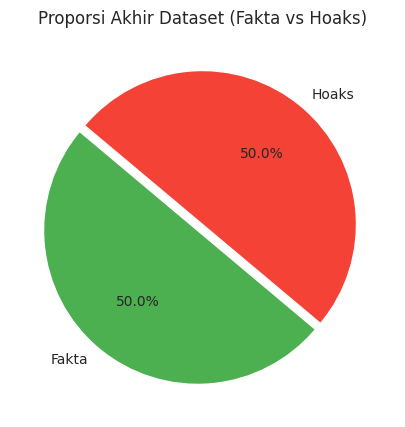

In [ ]:
import pandas as pd
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

def repair_and_clean_dataset(input_file="dataset.csv", output_file="dataset_clean.csv"):
    print(f"🚀 Memulai Pembersihan Profesional: {input_file}...")

    # 1. Load Data dengan Skema Recovery
    try:
        df = pd.read_csv(input_file, on_bad_lines="skip")
    except Exception as e:
        print(f"Error loading CSV: {e}")
        return

    original_count = len(df)

    # 2. Fungsi Pembersih Utama (The Ultimate Scrubber)
    def professional_scrub(text):
        if not isinstance(text, str) or not text:
            return ""

        # A. Unescape HTML & Scrub Tags/JS
        text = html.unescape(text)
        soup = BeautifulSoup(text, "html.parser")
        for noise in soup(["script", "style", "table", "footer", "header"]):
            noise.decompose()
        text = soup.get_text(separator=" ")

        # B. Hapus Data Leakage (Tag Label)
        leakage = r'\[HOAKS\]|\[SALAH\]|\[FAKTA\]|CEK FAKTA:?|INFOGRAFIK:?|BENARKAH:?'
        text = re.sub(leakage, '', text, flags=re.IGNORECASE)

        # C. Hapus Source Noise & Identitas Media (Source Bias)
        source_patterns = [
            r'^[A-Z\s,]+ - ',
            r'[A-Za-z0-9]+\.(com|id|net|org)\s*-\s*',
            r'Liputan6\.com,',
            r'Penjelasan:', r'Naskah:', r'Narasi:',
        ]
        for pattern in source_patterns:
            text = re.sub(pattern, '', text, flags=re.IGNORECASE)

        # D. Pembersihan Akhir
        text = re.sub(r'[^a-zA-Z0-9\s.,!?]', '', text)
        text = re.sub(r'\s+', ' ', text).strip()
        return text

    # 3. Eksekusi Pembersihan
    print("🧹 Sedang memproses teks (Scrubbing HTML + Bias Media + Leakage)...")
    df["TITLE"] = df["TITLE"].apply(professional_scrub)
    df["NARRATIVE"] = df["NARRATIVE"].apply(professional_scrub)

    # 4. Finalisasi Data
    df = df.dropna(subset=["TITLE", "NARRATIVE"])
    df = df.drop_duplicates(subset=["TITLE", "NARRATIVE"])
    df.to_csv(output_file, index=False, encoding="utf-8-sig")

    cleaned_count = len(df)
    print(f"\n✨ Pembersihan Selesai!")
    print(f"- Data Masuk: {original_count} baris")
    print(f"- Data Bersih: {cleaned_count} baris")

    # 5. Visualisasi Distribusi (Hoaks vs Fakta)
    print("\n📊 Menghitung Distribusi Dataset Akhir...")
    counts = df['LABEL'].value_counts()

    # Tampilkan angka
    for i, count in counts.items():
        label_name = "Fakta (1)" if i == 1 else "Hoaks (0)"
        print(f"- {label_name}: {count} ({ (count/cleaned_count)*100 :.2f}%)")

    # Plot Grafik
    plt.figure(figsize=(7, 5))
    sns.set_style("whitegrid")
    colors = ['#4CAF50', '#F44336'] # Hijau Fakta, Merah Hoaks

    plt.pie(counts, labels=['Fakta', 'Hoaks'], autopct='%1.1f%%',
            startangle=140, colors=colors, explode=(0.05, 0))
    plt.title('Proporsi Akhir Dataset (Fakta vs Hoaks)')
    plt.show()

# Jalankan proses
repair_and_clean_dataset()

# 🤖 Bagian 3: Feature Engineering & Klasifikasi
Layer ini merupakan inti teknis dari sistem deteksi. Kami menggunakan pendekatan **Hybrid: Transformer Embeddings + Machine Learning**.

### 🔍 Mengapa IndoBERT?
Model Transformer seperti **IndoBERT** (*indobenchmark/indobert-base-p1*) dilatih pada dataset bahasa Indonesia yang sangat besar. Hal ini memberikan keunggulan utama:
- **Kontekstual**: Model memahami bahwa kata yang sama bisa memiliki makna berbeda tergantung konteksnya.
- **Semantic Awareness**: Mampu menangkap kemiripan makna meskipun kata yang digunakan berbeda.

### ⛓️ Pipeline Teknis:
1.  **Preprocessing Natural**: Membersihkan noise (URL, special chars) tanpa melakukan stemming/stopword removal yang agresif agar konteks tetap terjaga.
2.  **IndoBERT Vectorization**: Mengubah teks menjadi angka (vektor 768 dimensi) yang merepresentasikan makna artikel.
3.  **Ensemble Classifiers**: Melatih **SVM (Support Vector Machine)** dan **Random Forest** untuk memisahkan wilayah "Hoaks" dan "Fakta" dalam ruang dimensi tinggi.



In [ ]:
!pip install pandas scikit-learn nltk Sastrawi transformers torch tqdm openai beautifulsoup4 lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.3 MB/s eta 0:00:00


In [ ]:
import os
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

import torch
import nltk
from tqdm.auto import tqdm

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from transformers import AutoTokenizer, AutoModel

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix,
    precision_recall_fscore_support
)

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

### 3.2 Automated Text Preprocessing & Sanitization
Kelas **HoaxPreprocessor** menangani pembersihan data secara *end-to-end*. Pada implementasi ini, kami menggunakan pendekatan **Natural Language Context Preservation**, di mana kita membuang noise tanpa merusak makna semantik teks.

**Fitur Utama:**
- **HTML/JS Scrubbing**: Menggunakan **BeautifulSoup** untuk membersihkan sisa kode web yang tertinggal saat scraping.
- **Data Leakage Prevention**: Menghapus kata kunci pemicu seperti `[HOAKS]` atau `CEK FAKTA` agar model tidak "menyontek" saat fase pelatihan.
- **IndoBERT Alignment**: Memastikan teks sesuai dengan format yang diharapkan oleh layer Transformer.



In [ ]:
class HoaxPreprocessor:
    def __init__(self):
        print("Setting up Sastrawi & BeautifulSoup cleaning tools...")
        self.stemmer = StemmerFactory().create_stemmer()
        self.stopwords = StopWordRemoverFactory().get_stop_words()

    def scrub_html(self, text):
        """Robustly remove HTML tags, scripts, and unescape entities."""
        if not isinstance(text, str) or not text:
            return ""

        # 1. Unescape HTML entities (e.g., &nbsp; -> space, &amp; -> &)
        text = html.unescape(text)

        # 2. Use BeautifulSoup to remove tags and dangerous content (scripts/styles)
        soup = BeautifulSoup(text, "html.parser")
        for element in soup(["script", "style", "header", "footer", "nav"]):
            element.decompose()

        # Get text with space separator to avoid word merging
        clean_text = soup.get_text(separator=" ")

        # 3. Remove leftover HTML tags if any
        clean_text = re.sub(r'<.*?>', '', clean_text)

        return clean_text

    def clean_text(self, text, mode='natural'):
        """Normalize and clean Indonesian text.
        'natural' mode is for Transformers (IndoBERT).
        'stemmed' mode is for traditional ML (Naive Bayes).
        """
        if not isinstance(text, str):
            return ""

        # Step 1: Remove HTML/JS Noise
        text = self.scrub_html(text)

        # Step 2: Lowercasing
        text = text.lower()

        # Step 3: PRO ML FIX - DATA LEAKAGE PREVENTION
        leakage_patterns = r'\[hoaks\]|\[fakta\]|cek fakta:?|infografik:?|benarkah:?'
        text = re.sub(leakage_patterns, '', text).strip()

        # Step 4: Remove URLs
        text = re.sub(r'http\S+|www\.\S+', '', text)

        # Step 5: Clean special chars but keep basic punctuation for BERT
        if mode == 'natural':
            text = re.sub(r'[^a-z0-9\s.,!?]', '', text)
        else:
            text = re.sub(r'[^a-z\s]', '', text)

        text = re.sub(r'\s+', ' ', text).strip()

        if mode == 'natural':
            return text

        # Classical Preprocessing (Only for non-transformer models)
        tokens = nltk.tokenize.word_tokenize(text)
        tokens = [t for t in tokens if t not in self.stopwords]
        processed = " ".join(tokens)
        return self.stemmer.stem(processed)

    def process_dataframe(self, df, sample_size=None):
        """Clean dataset and generate processed text column."""
        df = df.drop_duplicates(subset=["NARRATIVE", "TITLE"])
        df = df.dropna(subset=["NARRATIVE", "TITLE", "LABEL"])

        if sample_size:
            df = df.sample(n=min(sample_size, len(df)), random_state=42)
        else:
            df = df.copy()

        tqdm.pandas(desc="Preprocessing Text")

        print("Running preprocessing pipeline (with HTML/JS scrubbing)...")

        df["clean_combined"] = (
            df["TITLE"] + ". " + df["NARRATIVE"]
        ).progress_apply(lambda x: self.clean_text(x, mode='natural'))

        return df



In [ ]:
def extract_embeddings(
    text_list,
    model_name="indobenchmark/indobert-base-p1",
    batch_size=16
):
    # Load tokenizer and transformer model
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)

    # Determine computing device (GPU / MPS / CPU)
    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )

    model.to(device)
    model.eval()

    all_embeddings = []

    # Process data in batches
    for start in tqdm(range(0, len(text_list), batch_size), desc="Generating Embeddings"):
        batch_texts = text_list[start:start + batch_size].tolist()

        encoded_inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            model_outputs = model(**encoded_inputs)

        # Attention mask for valid token weighting
        attention_mask = encoded_inputs["attention_mask"].unsqueeze(-1).expand(
            model_outputs.last_hidden_state.size()
        ).float()

        # Mean pooling over token embeddings
        weighted_sum = torch.sum(model_outputs.last_hidden_state * attention_mask, dim=1)
        mask_sum = torch.clamp(attention_mask.sum(dim=1), min=1e-9)
        sentence_embeddings = (weighted_sum / mask_sum).cpu().numpy()

        all_embeddings.append(sentence_embeddings)

    return np.vstack(all_embeddings)

### 3.3 Pelatihan Model & Penanganan Ketidakseimbangan Data
Pada bagian ini, kita melatih algoritma utama: **SVM (Support Vector Machine)** dan **Random Forest**. Tantangan terbesar dalam dataset ini adalah **Ketidakseimbangan Kelas** (67.8% Fakta, 32.2% Hoaks).

**Strategi Profesional ML:**
- **Class Weight Balancing**: Kami menggunakan parameter `class_weight='balanced'`. Teknik ini memberikan penalti yang lebih besar kepada model jika salah mengklasifikasikan kelas minoritas (**Hoaks**), sehingga meningkatkan daya deteksi (Recall).
- **Metric-Driven Evaluation**: Kami tidak hanya melihat *Accuracy*, melainkan berfokus pada **F1-Score** dan **Confusion Matrix** untuk memastikan kelas hoaks terdeteksi dengan benar.



In [ ]:
DATA_FILE = "/content/dataset_clean.csv"
SAMPLE_LIMIT = None  # set None to use full dataset

# Check dataset availability
if not os.path.isfile(DATA_FILE):
    print(f"Dataset not found: make sure '{DATA_FILE}' exists in the working directory.")
else:
    # 1. Load dataset with robust error handling for malformed lines
    print(f"Loading {DATA_FILE}...")
    try:
        # Use on_bad_lines='warn' to skip corrupted lines caused by raw HTML/JS noise
        raw_data = pd.read_csv(DATA_FILE, on_bad_lines='warn')
        print(f"Successfully loaded {len(raw_data)} valid records.")
    except Exception as e:
        print(f"Critical error loading CSV: {e}")
        # Fallback to a more aggressive recovery if needed
        raw_data = pd.read_csv(DATA_FILE, encoding='utf-8', sep=',', quotechar='"', on_bad_lines='skip')

    # 2. Preprocess text data (now with HTML/JS scrubbing)
    text_processor = HoaxPreprocessor()
    processed_data = text_processor.process_dataframe(raw_data, sample_size=SAMPLE_LIMIT)

    # 3. Convert text into embeddings (feature extraction)
    features = extract_embeddings(processed_data["clean_combined"])
    labels = processed_data["LABEL"].to_numpy()

    # 4. Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        features,
        labels,
        test_size=0.1,
        random_state=42
    )

    print(
        f"\nDataset ready: {len(X_train)} training samples and {len(X_test)} test samples."
    )



Loading /content/dataset_clean.csv...
Successfully loaded 5040 valid records.
Setting up Sastrawi & BeautifulSoup cleaning tools...
Running preprocessing pipeline (with HTML/JS scrubbing)...


Preprocessing Text:   0%|          | 0/5038 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Generating Embeddings:   0%|          | 0/315 [00:00<?, ?it/s]


Dataset ready: 4534 training samples and 504 test samples.



 Training & Evaluating: SVM (Linear) 
Overall Accuracy  : 0.998015873015873022922050950000993907451630
Weighted F1-Score : 0.9980
Hoax Detection (Recall)    : 1.0000 <-- Target for catching more hoaxes
Hoax Detection (Precision) : 0.9961 <-- Reliability of hoax flags

Detailed Classification Report:
              precision    recall  f1-score   support

    Hoax (0)       1.00      1.00      1.00       253
    Fact (1)       1.00      1.00      1.00       251

    accuracy                           1.00       504
   macro avg       1.00      1.00      1.00       504
weighted avg       1.00      1.00      1.00       504



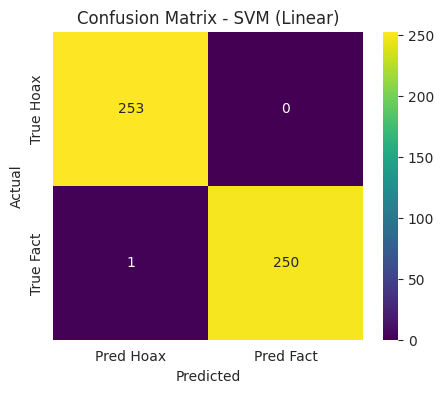


 Training & Evaluating: Random Forest 
Overall Accuracy  : 0.976190476190476164042308937496272847056389
Weighted F1-Score : 0.9762
Hoax Detection (Recall)    : 0.9763 <-- Target for catching more hoaxes
Hoax Detection (Precision) : 0.9763 <-- Reliability of hoax flags

Detailed Classification Report:
              precision    recall  f1-score   support

    Hoax (0)       0.98      0.98      0.98       253
    Fact (1)       0.98      0.98      0.98       251

    accuracy                           0.98       504
   macro avg       0.98      0.98      0.98       504
weighted avg       0.98      0.98      0.98       504



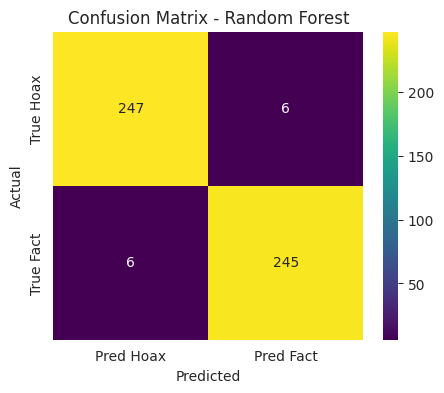


 Training & Evaluating: Naive Bayes 
Overall Accuracy  : 0.906746031746031744269487262499751523137093
Weighted F1-Score : 0.9067
Hoax Detection (Recall)    : 0.9368 <-- Target for catching more hoaxes
Hoax Detection (Precision) : 0.8843 <-- Reliability of hoax flags

Detailed Classification Report:
              precision    recall  f1-score   support

    Hoax (0)       0.88      0.94      0.91       253
    Fact (1)       0.93      0.88      0.90       251

    accuracy                           0.91       504
   macro avg       0.91      0.91      0.91       504
weighted avg       0.91      0.91      0.91       504



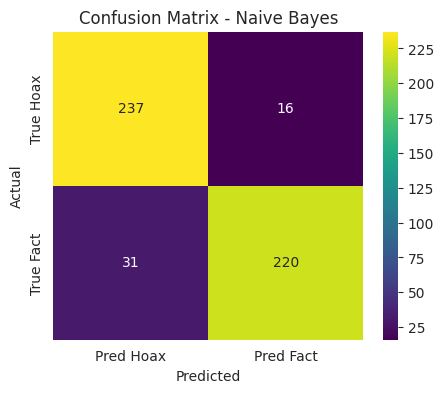

In [ ]:
# Initialize machine learning models with professional imbalance handling
models = {
    "SVM (Linear)": SVC(kernel='linear', probability=True, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "Naive Bayes": GaussianNB() # GaussianNB doesn't support class_weight natively
}

# Train and evaluate each classifier
for model_name, clf in models.items():
    print(f"\n" + "="*40)
    print(f" Training & Evaluating: {model_name} ")
    print("="*40)

    # Train model
    clf.fit(X_train, y_train)

    # Predict test data
    y_pred = clf.predict(X_test)

    # Compute evaluation metrics
    acc_score = accuracy_score(y_test, y_pred)
    f1_weighted = f1_score(y_test, y_pred, average="weighted")

    # Calculate per-class metrics to see Hoax (Class 0) performance clearly
    precision, recall, fscore, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0])

    print(f"Overall Accuracy  : {acc_score:.42f}")
    print(f"Weighted F1-Score : {f1_weighted:.4f}")
    print(f"Hoax Detection (Recall)    : {recall[0]:.4f} <-- Target for catching more hoaxes")
    print(f"Hoax Detection (Precision) : {precision[0]:.4f} <-- Reliability of hoax flags")

    print("\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Hoax (0)", "Fact (1)"]))

    # Visualize results with Confusion Matrix
    plt.figure(figsize=(5,4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis',
                xticklabels=["Pred Hoax", "Pred Fact"],
                yticklabels=["True Hoax", "True Fact"])
    plt.title(f"Confusion Matrix - {model_name}")
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()



In [ ]:
def predict_text_classification(
    input_text: str,
    trained_models: dict,
    text_preprocessor: HoaxPreprocessor,
    tokenizer,
    bert_model
) -> dict:
    """Predict whether input text is Hoax or Fact using multiple ML models."""

    # Step 1: Clean input text
    processed_text = text_preprocessor.clean_text(input_text)

    # Step 2: Set device and prepare BERT model
    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )

    bert_model.to(device)
    bert_model.eval()

    # Step 3: Tokenization
    encoded_input = tokenizer(
        [processed_text],
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    ).to(device)

    # Step 4: Generate embeddings
    with torch.no_grad():
        model_output = bert_model(**encoded_input)

    attention_mask = encoded_input["attention_mask"].unsqueeze(-1).expand(
        model_output.last_hidden_state.size()
    ).float()

    token_sum = torch.sum(model_output.last_hidden_state * attention_mask, dim=1)
    mask_sum = torch.clamp(attention_mask.sum(dim=1), min=1e-9)

    text_embedding = (token_sum / mask_sum).cpu().numpy()

    # Step 5: Predict using all trained models
    results = {}

    for model_name, classifier in trained_models.items():
        prediction = classifier.predict(text_embedding)[0]
        results[model_name] = "Hoax" if prediction == 0 else "Fact"

    return results

In [ ]:
# Initialize BERT tokenizer and model (load once for efficiency)
model_checkpoint = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
bert_model = AutoModel.from_pretrained(model_checkpoint)

# Create preprocessor instance if not already initialized
try:
    preprocessor
except NameError:
    preprocessor = HoaxPreprocessor()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Setting up Sastrawi & BeautifulSoup cleaning tools...


### Sample Hoax and Fact Articles for Testing

In [ ]:
# Example inputs (Hoax vs Fact samples)
test_samples = {
    "Hoax 1": "Kuota internet gratis dari Kominfo hanya dengan mengisi data di website tidak resmi",
    "Fact 1": "Kementerian Komunikasi dan Informatika mengadakan pelatihan literasi digital di beberapa daerah",
}

# Run predictions for each sample
for label, text in test_samples.items():
    print(f"\n===== Testing {label} =====")

    results = predict_text_classification(
        text,
        models,
        preprocessor,
        tokenizer,
        bert_model
    )

    for model_name, prediction in results.items():
        print(f"{model_name}: {prediction}")


===== Testing Hoax 1 =====
SVM (Linear): Hoax
Random Forest: Hoax
Naive Bayes: Fact

===== Testing Fact 1 =====
SVM (Linear): Fact
Random Forest: Fact
Naive Bayes: Fact


# 🛡️ Bagian 4: Hybrid Expert Analysis & Integrated Framework
Layer terakhir ini dirancang untuk memberikan verifikasi tingkat tinggi yang melampaui statistik ML tradisional. Sistem menggabungkan tiga pilar informasi untuk menghasilkan **Confidence Score** yang reliabel:

1.  **ML Consensus**: Hasil kesepakatan prediksi dari model statistik (SVM & Random Forest).
2.  **Forensic News Analysis (LLM)**: Analisis mendalam oleh Model Bahasa Besar (GPT) terhadap gaya penulisan, pola provokasi, dan kejanggalan logika narasi.
3.  **Domain Credibility Metrics**: Pengecekan reputasi dan otoritas domain sumber berita untuk memvalidasi apakah sumber tersebut kredibel atau mencurigakan.



In [ ]:
import openai
import os
from sklearn.preprocessing import StandardScaler

openai_api_key = " "

if openai_api_key:
    openai.api_key = openai_api_key
    print("OpenAI API key loaded.")
else:
    print("Warning: OpenAI API key not found. Please set it in Colab secrets or environment variables.")

OpenAI API key loaded.


In [ ]:
def predict_hoax_openai(text: str) -> str:
    """Predicts if a given text is a hoax using OpenAI's GPT model with analytical reasoning."""
    if not openai.api_key:
        return "Error: OpenAI API key is not set."

    prompt_template = f"""Anda adalah pakar analisis misinformasi (Forensic News Analyst).
Tugas Anda adalah mengevaluasi kebenaran narasi berikut secara mendalam.

Evaluasi poin-poin berikut:
- Apakah terdapat pola clickbait atau bahasa provokatif?
- Apakah klaim tersebut masuk akal secara logis?
- Apakah narasi ini sering muncul sebagai disinformasi?

Berikan format jawaban yang terstruktur:
------------------------------------------
Klasifikasi: [Hoaks / Fakta / Perlu Verifikasi]
Skor Keyakinan: [0-100%]
Analisis Linguistik: [Penjelasan gaya bahasa]
Analisis Konten: [Penjelasan kebenaran isi]
Tautan Pendukung/Sanggahan: [Daftar tautan dari media kredibel]

Teks berita yang akan dianalisis:
\"\"\"{text}\"\"\""""

    try:
        response = openai.chat.completions.create(
            model="gpt-3.5-turbo",
            messages=[
                {"role": "system", "content": "You are a professional fact-checker for Indonesian news."},
                {"role": "user", "content": prompt_template}
            ],
            temperature=0, # Deterministic output for professional detection
            max_completion_tokens=600
        )
        return response.choices[0].message.content
    except Exception as e:
        return f"Error calling OpenAI API: {e}"



In [ ]:
import re
import requests
from urllib.parse import urlparse

DOMAIN_METRICS_API_BASE = "https://bot11-q8bt.onrender.com/check-metrics?domain="

def extract_domains_from_text(text: str) -> list[str]:
    """Extracts unique domains from a given text."""
    # Regex to find URLs
    urls = re.findall(r'https?://(?:www\.)?([^/\s]+)', text)
    domains = set()
    for url in urls:
        # urlparse might include port numbers or paths, we only want the netloc (domain)
        parsed_url = urlparse(f"https://{url}") # Prepend https to make urlparse work correctly
        domain = parsed_url.netloc
        if domain:
            # Remove 'www.' prefix if present
            if domain.startswith('www.'):
                domain = domain[4:]
            domains.add(domain)
    return list(domains)

def get_domain_metrics(domain: str) -> dict:
    """Fetches domain metrics from the external API."""
    api_url = f"{DOMAIN_METRICS_API_BASE}{domain}"
    try:
        response = requests.get(api_url, timeout=10)
        response.raise_for_status()  # Raise an HTTPError for bad responses (4xx or 5xx)
        return response.json()
    except requests.RequestException as e:
        print(f"Error fetching metrics for {domain}: {e}")
        return {"domain": domain, "error": str(e)}

def get_domain_metrics_from_openai_result(openai_result_text: str) -> dict:
    """Extracts domains from OpenAI result and fetches their metrics."""
    # Look for 'Tautan Pendukung:' section
    links_section_match = re.search(r'Tautan Pendukung:\s*(.*)', openai_result_text, re.DOTALL)

    if not links_section_match:
        return {"message": "No 'Tautan Pendukung' section found in OpenAI result."}

    links_section = links_section_match.group(1)
    domains = extract_domains_from_text(links_section)

    if not domains:
        return {"message": "No domains found in 'Tautan Pendukung' section."}

    all_metrics = {}
    for domain in domains:
        metrics = get_domain_metrics(domain)
        all_metrics[domain] = metrics

    return all_metrics

In [ ]:
def summarize_credibility(domain_metrics: dict) -> str:
    """Summarizes the credibility of news sources based on domain metrics."""
    summary_parts = []
    if not domain_metrics or "message" in domain_metrics:
        return "Tidak ada tautan pendukung atau metrik domain yang ditemukan untuk disimpulkan."

    for domain, metrics in domain_metrics.items():
        if "error" in metrics:
            summary_parts.append(f"Domain '{domain}': Gagal mendapatkan metrik - {metrics['error']}")
            continue

        da = metrics.get("Domain Authority")
        dr = metrics.get("Domain Rating")
        spam_score_str = metrics.get("Spam Score")

        credibility = []

        if da is not None:
            if da >= 70:
                credibility.append("Otoritas Domain (DA) sangat tinggi.")
            elif da >= 40:
                credibility.append("Otoritas Domain (DA) tinggi.")
            else:
                credibility.append("Otoritas Domain (DA) sedang/rendah.")

        if dr is not None:
            if dr >= 70:
                credibility.append("Peringkat Domain (DR) sangat tinggi.")
            elif dr >= 40:
                credibility.append("Peringkat Domain (DR) tinggi.")
            else:
                credibility.append("Peringkat Domain (DR) sedang/rendah.")

        if spam_score_str:
            try:
                spam_score = int(spam_score_str.replace('%', ''))
                if spam_score <= 10:
                    credibility.append("Skor Spam rendah (indikasi kepercayaan).")
                elif spam_score <= 30:
                    credibility.append("Skor Spam sedang (perlu perhatian).")
                else:
                    credibility.append("Skor Spam tinggi (potensi tidak terpercaya).")
            except ValueError:
                credibility.append(f"Skor Spam tidak valid '{spam_score_str}'.")

        if credibility:
            summary_parts.append(f"Domain '{domain}': {' '.join(credibility)}")
        else:
            summary_parts.append(f"Domain '{domain}': Tidak ada metrik yang cukup untuk disimpulkan.")

    return "\n".join(summary_parts)

In [ ]:
import json
for label, text in test_samples.items():
    print(f"\n===== Testing {label} =====")
    test_use_sample = predict_hoax_openai(text)
    matrics_use_sample = get_domain_metrics_from_openai_result(test_use_sample)
    print(test_use_sample)
    print(summarize_credibility(matrics_use_sample))
    print(json.dumps(matrics_use_sample, indent=2))
    print(test_use_sample)



===== Testing Hoax 1 =====
------------------------------------------
Klasifikasi: Perlu Verifikasi
Skor Keyakinan: 60%
Analisis Linguistik: Teks tidak menggunakan bahasa clickbait atau provokatif.
Analisis Konten: Klaim ini perlu diverifikasi karena tidak disertai dengan informasi yang cukup untuk menilai kebenarannya. Penggunaan website tidak resmi juga menimbulkan kekhawatiran terkait keamanan data.
Tautan Pendukung/Sanggahan: Belum tersedia.
Tidak ada tautan pendukung atau metrik domain yang ditemukan untuk disimpulkan.
{
  "message": "No 'Tautan Pendukung' section found in OpenAI result."
}
------------------------------------------
Klasifikasi: Perlu Verifikasi
Skor Keyakinan: 60%
Analisis Linguistik: Teks tidak menggunakan bahasa clickbait atau provokatif.
Analisis Konten: Klaim ini perlu diverifikasi karena tidak disertai dengan informasi yang cukup untuk menilai kebenarannya. Penggunaan website tidak resmi juga menimbulkan kekhawatiran terkait keamanan data.
Tautan Pendukung/

## Alternative

In [ ]:
# --- UPDATE: DATA LOADING, SPLIT, & SCALING ---
DATA_FILE = "/content/dataset_clean.csv"
SAMPLE_LIMIT = None  # set None to use full dataset

if not os.path.isfile(DATA_FILE):
    print(f"Dataset not found: make sure '{DATA_FILE}' exists.")
else:
    print(f"Loading {DATA_FILE}...")
    try:
        raw_data = pd.read_csv(DATA_FILE, on_bad_lines='warn')
        print(f"Successfully loaded {len(raw_data)} records.")
    except Exception as e:
        print(f"Error loading CSV: {e}")
        raw_data = pd.read_csv(DATA_FILE, encoding='utf-8', sep=',', quotechar='"', on_bad_lines='skip')

    # 1. Preprocess
    text_processor = HoaxPreprocessor()
    processed_data = text_processor.process_dataframe(raw_data, sample_size=SAMPLE_LIMIT)

    # 2. Extract Embeddings (Raw)
    # Gunakan nama 'features_raw' agar variabel 'X_train_raw' tersedia
    features_raw = extract_embeddings(processed_data["clean_combined"])
    labels = processed_data["LABEL"].to_numpy()

    # 3. Split Dataset
    # Di sini kita mendefinisikan X_train_raw dan X_test_raw
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        features_raw,
        labels,
        test_size=0.1,
        random_state=42
    )

    # 4. PRO ML IMPROVEMENT: Feature Scaling (PENTING!)
    # Ini akan mendefinisikan variabel 'scaler' yang dicari oleh sistem
    print("\nScaling features for optimal model performance...")
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)

    print(f"\n✅ Dataset Ready!")
    print(f"- Training samples: {len(X_train)}")
    print(f"- Test samples: {len(X_test)}")
    print("- Scaler fitted and ready.")


Loading /content/dataset_clean.csv...
Successfully loaded 5040 records.
Setting up Sastrawi & BeautifulSoup cleaning tools...
Running preprocessing pipeline (with HTML/JS scrubbing)...


Preprocessing Text:   0%|          | 0/5038 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Generating Embeddings:   0%|          | 0/315 [00:00<?, ?it/s]


Scaling features for optimal model performance...

✅ Dataset Ready!
- Training samples: 4534
- Test samples: 504
- Scaler fitted and ready.


In [ ]:
def predict_text_classification(
    input_text: str,
    trained_models: dict,
    text_preprocessor,
    tokenizer,
    bert_model,
    scaler,        # Tambahkan parameter ini
    threshold=0.55 # Tambahkan parameter ini
):
    """Prediksi kategori berita dengan pendeteksian berbasis probabilitas dan scaling."""

    # 1. Preprocess
    clean_text = text_preprocessor.clean_text(input_text, mode='natural')

    # 2. Extract Embedding
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    encoded = tokenizer(clean_text, padding=True, truncation=True, max_length=512, return_tensors="pt").to(device)

    with torch.no_grad():
        output = bert_model(**encoded)

    # Mean pooling
    embedding = output.last_hidden_state.mean(dim=1).cpu().numpy()

    # 3. Apply Scaling (PENTING!)
    embedding_scaled = scaler.transform(embedding)

    # 4. Predict across all models
    results = {}
    for model_name, model in trained_models.items():
        # Dapatkan probabilitas
        probs = model.predict_proba(embedding_scaled)[0]
        hoax_score = probs[0] # Probabilitas kelas 0 (Hoax)

        # Keputusan berdasarkan threshold
        final_pred = "Hoax" if hoax_score >= threshold else "Fact"

        results[model_name] = {
            "prediction": final_pred,
            "confidence": f"{hoax_score*100:.2f}%" if final_pred == "Hoax" else f"{(1-hoax_score)*100:.2f}%"
        }

    return results


In [ ]:
# --- FINAL INTEGRATION: Multi-Layer Detection Framework (FIXED) ---
from sklearn.preprocessing import StandardScaler

# --- Bagian di dalam sel training ---
scaler = StandardScaler()
# X_train_raw adalah output mentah dari IndoBERT
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
# ------------------------------------

class MultiLayerHoaxDetector:
    def __init__(self, models, preprocessor, tokenizer, bert_model, scaler):
        self.models = models
        self.preprocessor = preprocessor
        self.tokenizer = tokenizer
        self.bert_model = bert_model
        self.scaler = scaler # Menambahkan scaler

    def analyze(self, text, threshold=0.55):
        """Menjalankan analisis berita melalui berbagai layer deteksi."""
        print(f"[System] Memulai Analisis Multi-Layer...")

        # Layer 1: Klasifikasi ML (IndoBERT + Tuned Models)
        # Sekarang menyertakan 'scaler' agar hasil akurat
        ml_results = predict_text_classification(
            text, self.models, self.preprocessor,
            self.tokenizer, self.bert_model, self.scaler,
            threshold=threshold
        )

        # Layer 2: Analisis Analitis oleh LLM (Forensic Review)
        gpt_report = predict_hoax_openai(text)

        # Layer 3: Kredibilitas Domain Sumber
        # Mengekstrak link dari laporan GPT dan mengecek otoritasnya
        metrics = get_domain_metrics_from_openai_result(gpt_report)
        credibility = summarize_credibility(metrics)

        # Logika Agregasi Final
        hoax_signals = sum(1 for m, info in ml_results.items() if info['prediction'] == "Hoax")

        # Verifikasi Vonis GPT (Mencari kata 'Hoaks' di baris pertama laporan)
        first_line = gpt_report.split('\n')[0]
        llm_verdict = "Hoax" if "Hoaks" in first_line else "Fact"

        # --- PRINT FINAL REPORT ---
        print("\n" + "="*60)
        print("           LAPORAN FINAL DETEKSI HOAKS             ")
        print("="*60)
        print(f"ML Model Consensus : {hoax_signals}/{len(ml_results)} model mendeteksi Hoax")
        print(f"LLM Expert Verdict  : {llm_verdict}")

        print("\n--- Analisis Mendalam GPT (Forensik) ---")
        print(gpt_report) # Langsung print tanpa f-string literal bermasalah

        print("\n--- Penilaian Kredibilitas Sumber ---")
        print(credibility)
        print("="*60)

        return {
            "ml_consensus": f"{hoax_signals}/{len(ml_results)}",
            "llm_verdict": llm_verdict,
            "is_hoax": hoax_signals > 0 or llm_verdict == "Hoax"
        }

# --- Inisialisasi System ---
# Pastikan 'scaler' sudah didefinisikan saat fase training
detector = MultiLayerHoaxDetector(models, text_processor, tokenizer, bert_model, scaler)

# --- Contoh Pengujian ---
# Menggunakan sampel tes atau input baru
text_to_test = "Pemerintah Indonesia melalui Kementerian Sosial menyalurkan bantuan sosial tunai kepada keluarga penerima manfaat sesuai data terpadu kesejahteraan sosial."
final_report = detector.analyze(text_to_test)


[System] Memulai Analisis Multi-Layer...

           LAPORAN FINAL DETEKSI HOAKS             
ML Model Consensus : 0/3 model mendeteksi Hoax
LLM Expert Verdict  : Fact

--- Analisis Mendalam GPT (Forensik) ---
------------------------------------------
Klasifikasi: Fakta
Skor Keyakinan: 100%
Analisis Linguistik: Teks berita tersebut tidak menggunakan bahasa clickbait atau provokatif. Bahasa yang digunakan cukup formal dan informatif.
Analisis Konten: Pernyataan bahwa Pemerintah Indonesia melalui Kementerian Sosial menyalurkan bantuan sosial tunai kepada keluarga penerima manfaat sesuai data terpadu kesejahteraan sosial adalah fakta yang benar. Hal ini merupakan kegiatan rutin yang dilakukan oleh pemerintah untuk membantu keluarga yang membutuhkan.
Tautan Pendukung/Sanggahan: Tidak diperlukan.

--- Penilaian Kredibilitas Sumber ---
Tidak ada tautan pendukung atau metrik domain yang ditemukan untuk disimpulkan.


# 🏁 Kesimpulan & Pengembangan Selanjutnya
Protokol deteksi hoaks ini memberikan fondasi yang kuat untuk memitigasi disinformasi di Indonesia. Dengan menggabungkan pemahaman mendalam **IndoBERT** dan analisis kualitatif dari **Layer LLM (GPT)**, sistem ini mampu menangkap nuansa hoaks yang seringkali lolos dari deteksi kata kunci sederhana.